For this little example i wanted to understand PCA on data and how it works. 
Here's the different step
Center the data
Covariance matrix
eigenvalus and vectors
projections onto principal components
reconstruction
plot 1 : the centered clouds with all the pincipal components
plot 2 : projection on the lst component
plot 3: reconstruction from 1 component vs original

C:\Users\Moi\AppData\Local\Temp\ipykernel_5108\2497503292.py:8: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = rng.multivariate_normal(mean=[5, 2],


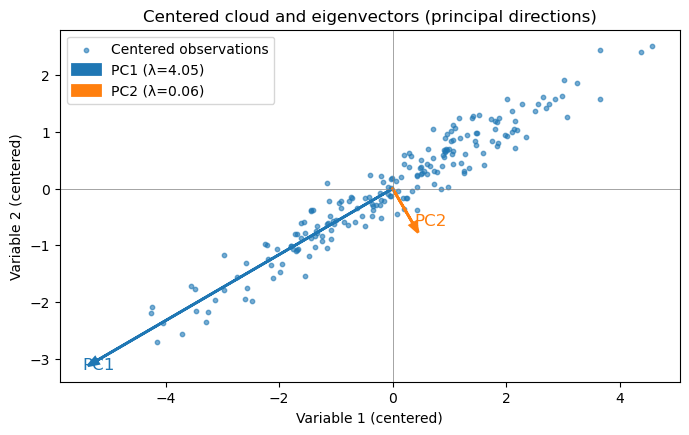

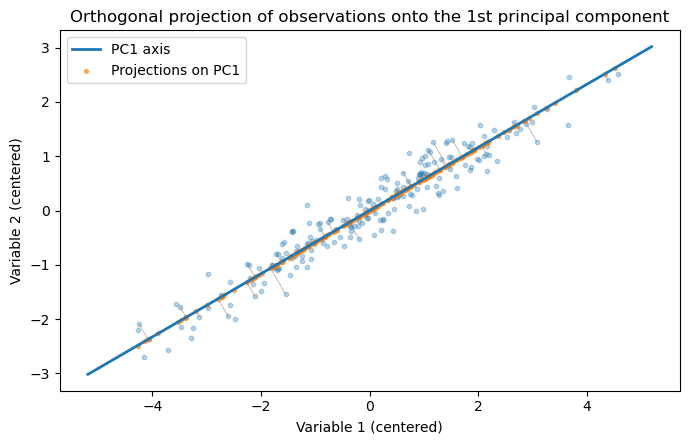

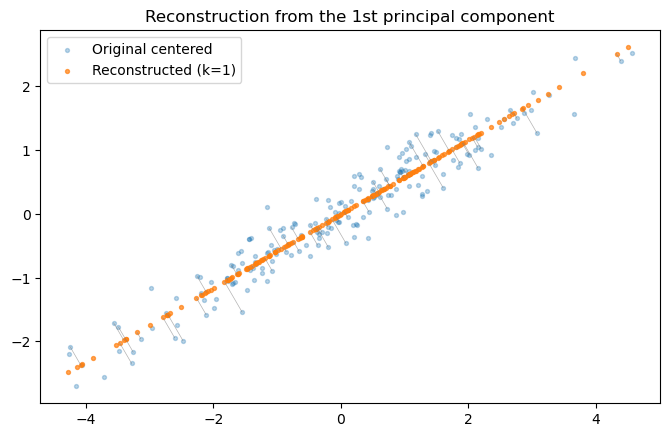

Eigenvalues: [4.0452 0.0568]
Explained variance ratio: [0.9862 0.0138]
Cumulative: [0.9862 1.    ]
Reconstruction error (k=1): 3.3616, (k=2): 0.0000


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def demo_pca_visual(n=200, random_state=0, show_reconstruction=True):
    rng = np.random.RandomState(random_state)

    # Generate a 2D anisotropic cloud
    X = rng.multivariate_normal(mean=[5, 2],
                                cov=[[3.0, 1.8],
                                     [1.8, 1.0]],
                                size=n)

    # Center by column
    Xc = X - X.mean(axis=0)

    # Covariance matrix (p x p)
    n_obs = Xc.shape[0]
    C = (1.0 / (n_obs - 1)) * Xc.T @ Xc

    # Spectral decomposition (eigenvalues and eigenvectors)
    eigvals, eigvecs = np.linalg.eigh(C)
    idx = eigvals.argsort()[::-1]
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]   # columns = eigenvectors (directions)

    # Projections (scores) onto principal components
    Z = Xc @ eigvecs            # (n, p); columns = coordinates along each component

    # Reconstruction from k components
    def reconstruct(k):
        Vk = eigvecs[:, :k]     # (p, k)
        Zk = Xc @ Vk            # (n, k)
        X_recon = Zk @ Vk.T     # (n, p)
        return X_recon

    # Plot 1: centered cloud + eigenvectors (scaled by sqrt(eigenvalue))
    plt.figure(figsize=(8, 8))
    plt.scatter(Xc[:, 0], Xc[:, 1], s=10, alpha=0.6, label='Centered observations')
    origin = np.zeros(2)
    scales = np.sqrt(eigvals)
    for i in range(eigvecs.shape[1]):
        v = eigvecs[:, i] * scales[i] * 3  # scale factor for visibility
        plt.arrow(origin[0], origin[1], v[0], v[1],
                  head_width=0.12, head_length=0.18, color=f"C{i}", linewidth=2,
                  label=f"PC{i+1} (λ={eigvals[i]:.2f})")
        plt.text(v[0]*1.05, v[1]*1.05, f"PC{i+1}", color=f"C{i}", fontsize=12)

    plt.gca().set_aspect('equal', 'box')
    plt.axhline(0, color='gray', linewidth=0.5)
    plt.axvline(0, color='gray', linewidth=0.5)
    plt.legend()
    plt.title("Centered cloud and eigenvectors (principal directions)")
    plt.xlabel("Variable 1 (centered)")
    plt.ylabel("Variable 2 (centered)")
    plt.show()

    # Plot 2: projection onto the 1st principal component (line + orthogonal projections)
    plt.figure(figsize=(8, 6))
    plt.scatter(Xc[:, 0], Xc[:, 1], s=10, alpha=0.3)
    pc1 = eigvecs[:, 0]
    t = np.linspace(-6, 6, 100)
    line = np.outer(t, pc1)
    plt.plot(line[:, 0], line[:, 1], color='C0', linewidth=2, label='PC1 axis')

    # orthogonal projections of points onto PC1
    Z1 = Xc @ pc1             # (n,) scalar coordinates on PC1
    proj = np.outer(Z1, pc1)  # (n,2) projected points in original space
    for xi, pi in zip(Xc[:40], proj[:40]):  # draw a few segments for clarity
        plt.plot([xi[0], pi[0]], [xi[1], pi[1]], color='gray', linewidth=0.6, alpha=0.6)
    plt.scatter(proj[:, 0], proj[:, 1], s=8, color='C1', alpha=0.6, label='Projections on PC1')

    plt.gca().set_aspect('equal', 'box')
    plt.title("Orthogonal projection of observations onto the 1st principal component")
    plt.legend()
    plt.xlabel("Variable 1 (centered)")
    plt.ylabel("Variable 2 (centered)")
    plt.show()

    # Plot 3: reconstruction from 1 component vs original
    if show_reconstruction:
        X1 = reconstruct(1)
        plt.figure(figsize=(8, 6))
        plt.scatter(Xc[:, 0], Xc[:, 1], s=8, alpha=0.3, label='Original centered')
        plt.scatter(X1[:, 0], X1[:, 1], s=8, alpha=0.7, label='Reconstructed (k=1)')
        for xi, xr in zip(Xc[:60], X1[:60]):  # a few segments to visualize reconstruction error
            plt.plot([xi[0], xr[0]], [xi[1], xr[1]], color='gray', linewidth=0.5, alpha=0.6)
        plt.gca().set_aspect('equal', 'box')
        plt.title("Reconstruction from the 1st principal component")
        plt.legend()
        plt.show()

    # Numeric prints
    total_var = eigvals.sum()
    explained = eigvals / total_var
    cum_explained = np.cumsum(explained)
    print("Eigenvalues:", np.round(eigvals, 4))
    print("Explained variance ratio:", np.round(explained, 4))
    print("Cumulative:", np.round(cum_explained, 4))
    # reconstruction errors
    X1 = reconstruct(1)
    err1 = np.linalg.norm(Xc - X1)
    X2 = reconstruct(2)
    err2 = np.linalg.norm(Xc - X2)
    print(f"Reconstruction error (k=1): {err1:.4f}, (k=2): {err2:.4f}")

# Run the demo
demo_pca_visual()


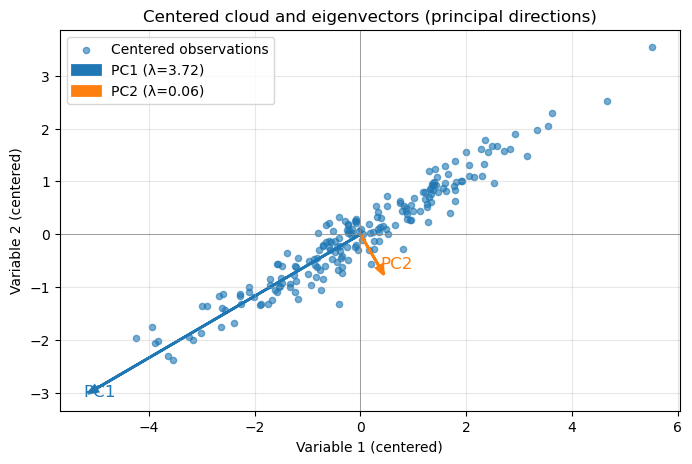

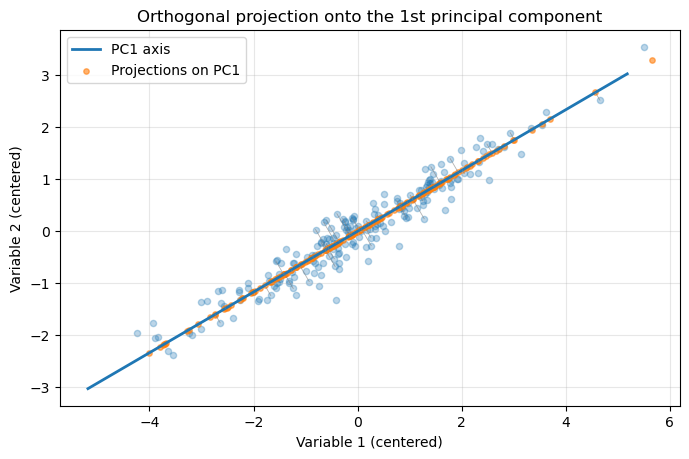

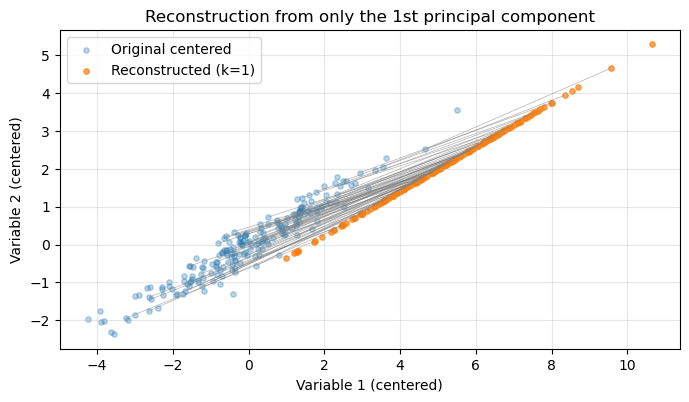

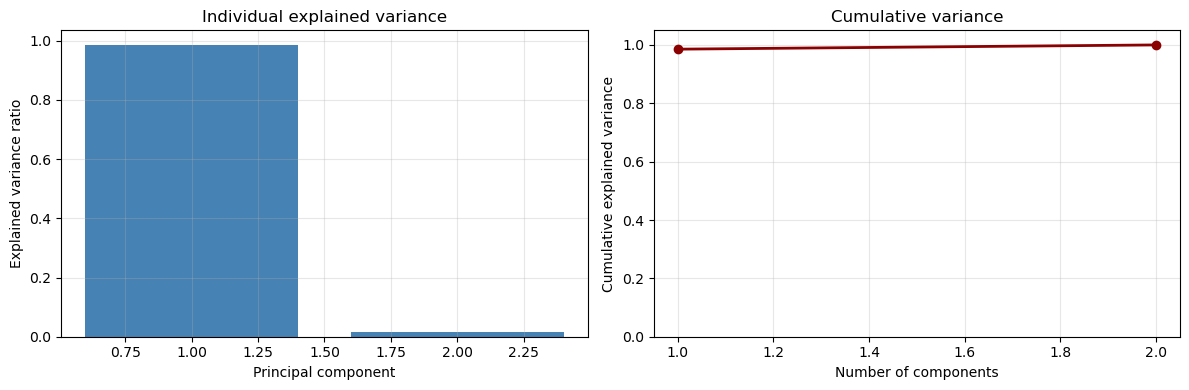

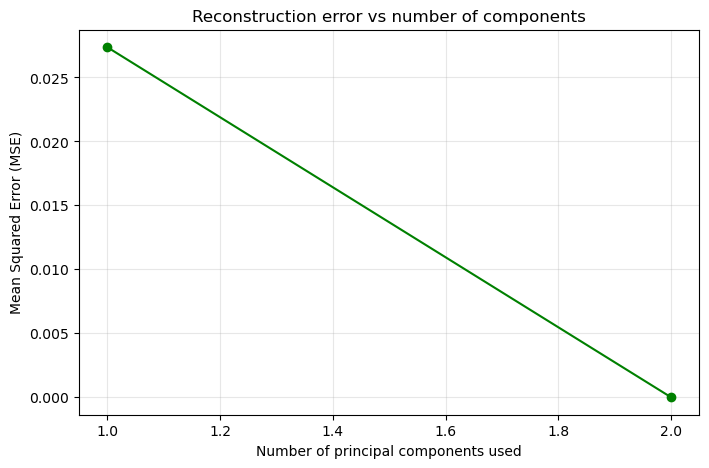


=== PCA Metrics (Synthetic Data) ===
Explained variance ratio: [0.9854 0.0146]
Cumulative explained variance: [0.9854 1.    ]
Reconstruction MSE (k=1): 0.0274
Reconstruction MSE (k=2): 0.0000
=== PCA on Iris Dataset (4 features) ===
Explained variance ratio: [0.9246 0.0531 0.0171 0.0052]
Cumulative explained variance: [0.9246 0.9777 0.9948 1.    ]


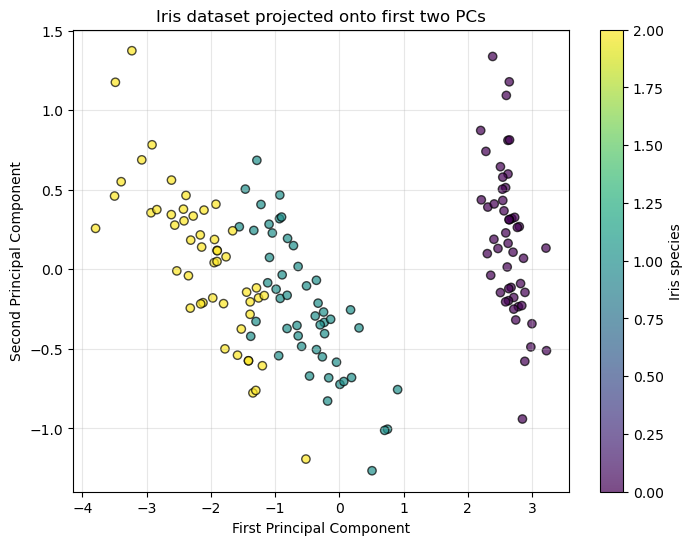


Loadings (original features on principal components):
sepal length (cm)    PC1: -0.3614  PC2: +0.0845
sepal width (cm)     PC1: +0.6566  PC2: +0.7302
petal length (cm)    PC1: +0.5820  PC2: -0.5979
petal width (cm)     PC1: +0.3155  PC2: -0.3197


In [ ]:
# %% [markdown]
# # PCA from Scratch: Understanding Dimensionality Reduction
# 
# **Goal**: Implement Principal Component Analysis step by step – centering, covariance, eigen‑decomposition, projection, reconstruction – to truly understand how it works. Validate against `sklearn` and visualise the effects.
# 
# Author: [Your Name]

# %% [markdown]
# ## 1. Imports and Configuration

# %%
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.datasets import load_iris
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42

# %% [markdown]
# ## 2. Custom PCA Implementation (sklearn‑like API)

# %%
class MyPCA:
    """
    Principal Component Analysis (PCA) implemented from scratch.
    
    Parameters
    ----------
    n_components : int, default=None
        Number of components to keep. If None, all components are kept.
    
    Attributes
    ----------
    components_ : ndarray of shape (n_features, n_components)
        Principal axes (eigenvectors) in feature space.
    explained_variance_ : ndarray of shape (n_components,)
        Variance explained by each selected component.
    explained_variance_ratio_ : ndarray of shape (n_components,)
        Percentage of variance explained by each component.
    mean_ : ndarray of shape (n_features,)
        Per-feature mean subtracted during fitting.
    n_features_in_ : int
        Number of features seen during fit.
    """
    
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        self.mean_ = None
        self.n_features_in_ = None
    
    def fit(self, X):
        """Fit the PCA model on the data."""
        X = np.asarray(X)
        self.mean_ = X.mean(axis=0)
        self.n_features_in_ = X.shape[1]
        
        # Center the data
        Xc = X - self.mean_
        n = Xc.shape[0]
        
        # Covariance matrix (biased or unbiased? We use unbiased: (n-1))
        C = Xc.T @ Xc / (n - 1)
        
        # Eigen decomposition
        eigvals, eigvecs = np.linalg.eigh(C)
        
        # Sort descending by eigenvalue
        idx = eigvals.argsort()[::-1]
        eigvals = eigvals[idx]
        eigvecs = eigvecs[:, idx]
        
        # Determine number of components
        n_components = self.n_components if self.n_components else X.shape[1]
        self.components_ = eigvecs[:, :n_components]
        self.explained_variance_ = eigvals[:n_components]
        total_var = eigvals.sum()
        self.explained_variance_ratio_ = self.explained_variance_ / total_var
        
        return self
    
    def transform(self, X):
        """Project the data onto the principal components."""
        X = np.asarray(X)
        Xc = X - self.mean_
        return Xc @ self.components_
    
    def fit_transform(self, X):
        """Fit the model and transform the data in one step."""
        self.fit(X)
        return self.transform(X)
    
    def inverse_transform(self, Z):
        """Reconstruct data from its projected representation.

        Accepts a projection `Z` that may contain fewer than the fitted
        number of components (e.g. shape (n_samples, k) with k <= n_components),
        or a 1-D array of shape (n_samples,).
        """
        Z = np.asarray(Z)
        if Z.ndim == 1:
            Z = Z.reshape(-1, 1)
        # number of components provided in Z
        k = Z.shape[1]
        comps = self.components_[:, :k]
        return Z @ comps.T + self.mean_

# ## 3. Validation: MyPCA vs sklearn

def validate_pca(X, n_components=None):
    """Compare MyPCA with sklearn's PCA on the same dataset."""
    if n_components is None:
        n_components = min(X.shape)
    
    my_pca = MyPCA(n_components=n_components)
    sk_pca = SklearnPCA(n_components=n_components)
    
    Z_my = my_pca.fit_transform(X)
    Z_sk = sk_pca.fit_transform(X)
    
    # sklearn's components_ are transposed and signs may flip
    # We compare absolute values or align signs
    comp_my = my_pca.components_
    comp_sk = sk_pca.components_.T  # make same shape (n_features, n_components)
    
    # Sign alignment (we can multiply by -1 if needed)
    sign_correction = np.sign(np.sum(comp_my * comp_sk, axis=0))
    sign_correction[sign_correction == 0] = 1
    comp_my_aligned = comp_my * sign_correction
    comp_sk_aligned = comp_sk
    
    print("Validation against sklearn.decomposition.PCA")
    print("-" * 40)
    print(f"Components match (abs tolerance 1e-6): {np.allclose(comp_my_aligned, comp_sk_aligned, atol=1e-6)}")
    print(f"Explained variance ratio match: {np.allclose(my_pca.explained_variance_ratio_, sk_pca.explained_variance_ratio_, atol=1e-6)}")
    print(f"Transformed data match (abs tolerance 1e-6): {np.allclose(Z_my, Z_sk, atol=1e-6)}")
    
    return my_pca, sk_pca

# %% [markdown]
# ## 4. Load / Generate Data
# 
# We'll use the Iris dataset (real) and also keep a synthetic 2D version for visual intuition.

# %%
# Real dataset: Iris (4 features)
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names = iris.feature_names

# Synthetic 2D anisotropic data (for visualising PCA mechanics)
rng = np.random.RandomState(RANDOM_STATE)
X_synth = rng.multivariate_normal(mean=[5, 2],
                                  cov=[[3.0, 1.8],
                                       [1.8, 1.0]],
                                  size=200)

# %% [markdown]
# ## 5. Demonstrate PCA on Synthetic 2D Data (Full Visualisation)

# %%
def demo_synthetic_pca(X, show_reconstruction_error_curve=True):
    """Full visualisation pipeline for 2D synthetic data."""
    pca = MyPCA(n_components=2)
    pca.fit(X)
    Xc = X - pca.mean_
    eigvals = pca.explained_variance_
    eigvecs = pca.components_
    
    # ---- Plot 1: Centered cloud + eigenvectors (scaled by sqrt(eigenvalue)) ----
    plt.figure(figsize=(8, 8))
    plt.scatter(Xc[:, 0], Xc[:, 1], s=20, alpha=0.6, label='Centered observations')
    origin = np.zeros(2)
    scales = np.sqrt(eigvals)
    for i in range(eigvecs.shape[1]):
        v = eigvecs[:, i] * scales[i] * 3  # scale for visibility
        plt.arrow(origin[0], origin[1], v[0], v[1],
                  head_width=0.12, head_length=0.18, color=f"C{i}", linewidth=2,
                  label=f"PC{i+1} (λ={eigvals[i]:.2f})")
        plt.text(v[0]*1.05, v[1]*1.05, f"PC{i+1}", color=f"C{i}", fontsize=12)
    
    plt.gca().set_aspect('equal', 'box')
    plt.axhline(0, color='gray', linewidth=0.5)
    plt.axvline(0, color='gray', linewidth=0.5)
    plt.legend()
    plt.title("Centered cloud and eigenvectors (principal directions)")
    plt.xlabel("Variable 1 (centered)")
    plt.ylabel("Variable 2 (centered)")
    plt.grid(alpha=0.3)
    plt.show()
    
    # ---- Plot 2: Projection onto the 1st principal component ----
    plt.figure(figsize=(8, 6))
    plt.scatter(Xc[:, 0], Xc[:, 1], s=20, alpha=0.3)
    pc1 = eigvecs[:, 0]
    t = np.linspace(-6, 6, 100)
    line = np.outer(t, pc1)
    plt.plot(line[:, 0], line[:, 1], color='C0', linewidth=2, label='PC1 axis')
    
    Z1 = Xc @ pc1
    proj = np.outer(Z1, pc1)
    # Plot a few projections
    for xi, pi in zip(Xc[:40], proj[:40]):
        plt.plot([xi[0], pi[0]], [xi[1], pi[1]], color='gray', linewidth=0.6, alpha=0.6)
    plt.scatter(proj[:, 0], proj[:, 1], s=15, color='C1', alpha=0.6, label='Projections on PC1')
    
    plt.gca().set_aspect('equal', 'box')
    plt.title("Orthogonal projection onto the 1st principal component")
    plt.legend()
    plt.xlabel("Variable 1 (centered)")
    plt.ylabel("Variable 2 (centered)")
    plt.grid(alpha=0.3)
    plt.show()
    
    # ---- Plot 3: Reconstruction from 1 component vs original ----
    Z = pca.transform(X)                     # (n,2)
    X_recon_1 = pca.inverse_transform(Z[:, :1])  # keep only PC1
    plt.figure(figsize=(8, 6))
    plt.scatter(Xc[:, 0], Xc[:, 1], s=15, alpha=0.3, label='Original centered')
    plt.scatter(X_recon_1[:, 0], X_recon_1[:, 1], s=15, alpha=0.7, label='Reconstructed (k=1)')
    for xi, xr in zip(Xc[:60], X_recon_1[:60]):
        plt.plot([xi[0], xr[0]], [xi[1], xr[1]], color='gray', linewidth=0.5, alpha=0.6)
    plt.gca().set_aspect('equal', 'box')
    plt.title("Reconstruction from only the 1st principal component")
    plt.legend()
    plt.xlabel("Variable 1 (centered)")
    plt.ylabel("Variable 2 (centered)")
    plt.grid(alpha=0.3)
    plt.show()
    
    # ---- Additional: Scree plot & cumulative explained variance ----
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    explained_ratio = pca.explained_variance_ratio_
    cum_ratio = np.cumsum(explained_ratio)
    ax1.bar(range(1, len(explained_ratio)+1), explained_ratio, color='steelblue')
    ax1.set_xlabel('Principal component')
    ax1.set_ylabel('Explained variance ratio')
    ax1.set_title('Individual explained variance')
    ax1.grid(alpha=0.3)
    
    ax2.plot(range(1, len(cum_ratio)+1), cum_ratio, 'o-', color='darkred', linewidth=2)
    ax2.set_xlabel('Number of components')
    ax2.set_ylabel('Cumulative explained variance')
    ax2.set_title('Cumulative variance')
    ax2.grid(alpha=0.3)
    ax2.set_ylim([0, 1.05])
    plt.tight_layout()
    plt.show()
    
    # ---- Reconstruction error curve (MSE vs number of components) ----
    if show_reconstruction_error_curve:
        max_comp = X.shape[1]
        errors = []
        for k in range(1, max_comp+1):
            Zk = pca.transform(X)[:, :k]
            X_recon = pca.inverse_transform(Zk)
            mse = np.mean((X - X_recon)**2)
            errors.append(mse)
        plt.figure(figsize=(8, 5))
        plt.plot(range(1, max_comp+1), errors, 'o-', color='green')
        plt.xlabel('Number of principal components used')
        plt.ylabel('Mean Squared Error (MSE)')
        plt.title('Reconstruction error vs number of components')
        plt.grid(alpha=0.3)
        plt.show()
    
    # Print metrics
    print("\n=== PCA Metrics (Synthetic Data) ===")
    print(f"Explained variance ratio: {np.round(explained_ratio, 4)}")
    print(f"Cumulative explained variance: {np.round(cum_ratio, 4)}")
    print(f"Reconstruction MSE (k=1): {errors[0]:.4f}")
    print(f"Reconstruction MSE (k=2): {errors[1]:.4f}")

# Run synthetic demo
demo_synthetic_pca(X_synth, show_reconstruction_error_curve=True)

# %% [markdown]
# ## 6. Apply PCA to Real Data (Iris Dataset)
# 
# Show that PCA can reduce from 4D to 2D while preserving ~95% of variance. Visualise the first two principal components.

# %%
# Fit PCA on Iris (full 4 components)
pca_iris = MyPCA(n_components=4)
Z_iris = pca_iris.fit_transform(X_iris)

# Print explained variance
print("=== PCA on Iris Dataset (4 features) ===")
print(f"Explained variance ratio: {np.round(pca_iris.explained_variance_ratio_, 4)}")
print(f"Cumulative explained variance: {np.round(np.cumsum(pca_iris.explained_variance_ratio_), 4)}")

# Plot first two principal components, coloured by target
plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z_iris[:, 0], Z_iris[:, 1], c=y_iris, cmap='viridis', edgecolor='k', alpha=0.7)
plt.colorbar(scatter, label='Iris species')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Iris dataset projected onto first two PCs')
plt.grid(alpha=0.3)
plt.show()

# Interpretation: loadings (coefficients of original features on PC1)
loadings = pca_iris.components_
print("\nLoadings (original features on principal components):")
for i, name in enumerate(feature_names):
    print(f"{name:20s} PC1: {loadings[0,i]:+.4f}  PC2: {loadings[1,i]:+.4f}")

# %% [markdown]
# ## 7. Discussion & Limitations
# 
# - **Advantages**: PCA is linear, fast, and interpretable. It decorrelates features.
# - **Limitations**: Assumes linear relationships; sensitive to feature scaling (we did not scale Iris intentionally, but in practice you should standardise unless features are comparable).
# - **When to use**: Visualisation (2D/3D), noise reduction, speeding up other models.
# - **When to avoid**: Non‑linear structures (use kernel PCA, t‑SNE, UMAP).

# %% [markdown]
# ## 8. References
# 
# - Pearson, K. (1901). "On Lines and Planes of Closest Fit to Systems of Points in Space".
# - Jolliffe, I.T. (2002). *Principal Component Analysis*.
# - `sklearn.decomposition.PCA` documentation.
